# Multi-model Tox21 shortcut audit: context sensitivity, conflict, and mitigation

This notebook reruns the two-stage study under **one consistent preprocessing and evaluation pipeline** and adds models beyond Random Forest.

## Models compared

- **Random Forest (RF):** retained as a conventional baseline, not treated as obsolete.
- **Extra Trees:** randomized tree ensemble.
- **XGBoost:** gradient-boosted trees on the same Morgan fingerprints.
- **LightGBM:** histogram-based gradient boosting on the same fingerprints.
- **MLP:** a feed-forward neural network on the same fingerprints.
- **Optional Chemprop D-MPNN:** a graph neural network that learns directly from molecular graphs; it is off by default because its per-fold training is slower and needs an additional package.

The fingerprint models share the same 2,048-bit Morgan representation, so differences are less confounded by representation choice. **Chemprop D-MPNN is included as an optional graph-model branch** for the three assays eligible in the prior alkyl-halide mitigation pilot. After confirming it works, set `CHEMPROP_ASSAYS = label_cols` to run all available assays. Chemprop v2 learns directly from molecular graphs rather than fixed fingerprints.

## Analyses

1. **Stage I:** out-of-fold ROC-AUC within molecules that share each motif.
2. **Stage II:** compare held-out agreement and conflict cases, with associations estimated from training folds only; compare against a motif-only baseline.
3. **Stage III:** for the nominated alkyl-halide motif, test fingerprint-bit masking and correlation-balanced training for RF, XGBoost, and LightGBM.
4. **Uncertainty:** cluster bootstrap by structural groups. Acyclic molecules are clustered by Morgan-fingerprint similarity rather than all being put into one empty-scaffold group.

This is a new, harmonized analysis. Do not mix these future results with the previous RF CSVs until the full rerun has completed. The earlier numerical results remain exploratory pilot results.

In [1]:
%pip install -q "scikit-learn>=1.7" xgboost lightgbm rdkit pandas numpy matplotlib requests

import os, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Cluster import Butina

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 20261017
DATA_PATH = None  # Optional local CSV, e.g. "tox21.csv"
N_SPLITS = 5
MIN_CLASS_COUNT = 10
MIN_TRAIN_MOTIF_N = 25
MIN_ASSOCIATION_DELTA = 0.10
MIN_BALANCE_CELL_N = 10
MAX_SAMPLE_WEIGHT = 8.0
N_ESTIMATORS = 250
MLP_MAX_ITER = 100

MODEL_NAMES = ["RF", "ExtraTrees", "XGBoost", "LightGBM", "MLP"]
# Mitigation is applied to RF plus two strong boosting methods to limit runtime.
MITIGATION_MODELS = ["RF", "XGBoost", "LightGBM"]
MITIGATION_MOTIF = "alkyl_halide"
# Optional graph model; run three assays first, then set CHEMPROP_ASSAYS = label_cols.
RUN_CHEMPROP_DMPNN = False
CHEMPROP_ASSAYS = ["SR-ARE", "SR-HSE", "SR-MMP"]
CHEMPROP_EPOCHS = 30
ACYCLIC_TANIMOTO_THRESHOLD = 0.60

TOX21_URLS = [
    "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz",
    "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/tox21.csv",
]
print("Imports ready. sklearn:", __import__("sklearn").__version__)
print("xgboost:", __import__("xgboost").__version__, "| lightgbm:", __import__("lightgbm").__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 43.0 MB/s eta 0:00:00
Imports ready. sklearn: 1.9.1
xgboost: 3.4.1 | lightgbm: 4.6.0


## 1. Load Tox21 and harmonize duplicate structures

Canonical SMILES are grouped into one molecule. For each assay, a label is kept only when the non-missing duplicate labels agree; conflicting duplicate labels become missing for that assay. This avoids the different duplicate-handling policies used by the two earlier notebooks.

In [2]:
data = None
load_errors = []
if DATA_PATH and os.path.exists(DATA_PATH):
    try:
        data = pd.read_csv(DATA_PATH)
        print(f"Loaded local file: {DATA_PATH}; shape={data.shape}")
    except Exception as e:
        load_errors.append(f"Local CSV: {type(e).__name__}: {e}")

if data is None:
    for url in TOX21_URLS:
        try:
            print("Trying", url)
            data = pd.read_csv(url)
            print("Loaded source data:", data.shape)
            break
        except Exception as e:
            load_errors.append(f"{url}: {type(e).__name__}: {e}")

if data is None:
    print("Tox21 could not be loaded. Set DATA_PATH to a local CSV and rerun this cell.")
    print("Errors:", load_errors)
else:
    if "smiles" not in data.columns:
        raise ValueError("Expected a 'smiles' column in the Tox21 CSV.")
    expected_assays = [
        "NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase", "NR-ER", "NR-ER-LBD",
        "NR-PPAR-gamma", "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"
    ]
    label_cols = [c for c in expected_assays if c in data.columns]
    if not label_cols:
        label_cols = [c for c in data.columns if c != "smiles" and
                      pd.to_numeric(data[c], errors="coerce").dropna().isin([0, 1]).all() and
                      pd.to_numeric(data[c], errors="coerce").notna().any()]
    if not label_cols:
        raise ValueError("No binary assay label columns were found.")

    valid_records = []
    invalid_smiles = 0
    for _, row in data.iterrows():
        mol = Chem.MolFromSmiles(str(row["smiles"]))
        if mol is None:
            invalid_smiles += 1
            continue
        valid_records.append({"canonical_smiles": Chem.MolToSmiles(mol), **{c: row[c] for c in label_cols}})

    valid_df = pd.DataFrame(valid_records)
    def resolve_duplicate_labels(values):
        vals = pd.to_numeric(pd.Series(values), errors="coerce").dropna().unique()
        vals = [float(v) for v in vals if float(v) in (0.0, 1.0)]
        return vals[0] if len(vals) == 1 else np.nan

    agg = {c: resolve_duplicate_labels for c in label_cols}
    clean = valid_df.groupby("canonical_smiles", as_index=False).agg(agg)
    mols = [Chem.MolFromSmiles(s) for s in clean["canonical_smiles"]]
    clean.index = np.arange(len(clean))
    print(f"Source rows: {len(data):,}; invalid SMILES: {invalid_smiles:,}; unique valid structures: {len(clean):,}")
    print("Assays:", label_cols)
    display(clean[label_cols].notna().sum().rename("observed_labels").to_frame())

Trying https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz
Loaded source data: (7831, 14)


[15:45:15] WARNING: not removing hydrogen atom without neighbors
[15:45:16] Explicit valence for atom # 8 Al, 6, is greater than permitted
[15:45:16] Explicit valence for atom # 3 Al, 6, is greater than permitted
[15:45:16] Explicit valence for atom # 4 Al, 6, is greater than permitted
[15:45:17] Explicit valence for atom # 4 Al, 6, is greater than permitted
[15:45:17] Explicit valence for atom # 9 Al, 6, is greater than permitted
[15:45:17] Explicit valence for atom # 5 Al, 6, is greater than permitted
[15:45:18] Explicit valence for atom # 16 Al, 6, is greater than permitted
[15:45:18] Explicit valence for atom # 20 Al, 6, is greater than permitted
[15:45:42] WARNING: not removing hydrogen atom without neighbors


Source rows: 7,831; invalid SMILES: 8; unique valid structures: 7,823
Assays: ['NR-AR', 'NR-AR-LBD', 'NR-AhR', 'NR-Aromatase', 'NR-ER', 'NR-ER-LBD', 'NR-PPAR-gamma', 'SR-ARE', 'SR-ATAD5', 'SR-HSE', 'SR-MMP', 'SR-p53']


,observed_labels
NR-AR,7258
NR-AR-LBD,6751
NR-AhR,6542
NR-Aromatase,5815
NR-ER,6186
NR-ER-LBD,6948
NR-PPAR-gamma,6443
SR-ARE,5825
SR-ATAD5,7065
SR-HSE,6460


## 2. Define candidate motifs and build Morgan fingerprints

The SMARTS patterns are operational subgroup definitions, not proof of a toxic mechanism. For bit ablation, RDKit's bit-environment metadata is retained so the notebook can identify fingerprint bits whose atom environments overlap the nominated motif in training molecules.

In [3]:
MOTIFS = {
    "nitro": "[N+](=O)[O-]",
    "aldehyde": "[CX3H1](=O)[#6]",
    "sulfonamide": "[SX4](=O)(=O)N",
    "aromatic_amine": "[c][NX3;H1,H2;!$(NC=O)]",
    "alkyl_halide": "[CX4][Cl,Br,I]",
    "epoxide_like": "[O;r3]1[C;r3][C;r3]1",
}
MOTIF_QUERIES = {name: Chem.MolFromSmarts(smarts) for name, smarts in MOTIFS.items()}
if any(q is None for q in MOTIF_QUERIES.values()):
    raise ValueError("Invalid SMARTS motif definition.")
if MITIGATION_MOTIF not in MOTIFS:
    raise ValueError("MITIGATION_MOTIF must be in MOTIFS.")

fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
rd_fps, X, fp_bit_info = [], np.zeros((len(mols), 2048), dtype=np.uint8), []
for i, mol in enumerate(mols):
    out = rdFingerprintGenerator.AdditionalOutput()
    out.AllocateBitInfoMap()
    fp = fpgen.GetFingerprint(mol, additionalOutput=out)
    rd_fps.append(fp)
    arr = np.zeros(2048, dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    X[i] = arr
    fp_bit_info.append({int(bit): tuple((int(center), int(radius)) for center, radius in envs)
                        for bit, envs in out.GetBitInfoMap().items()})

motif_df = pd.DataFrame({name: [int(m.HasSubstructMatch(query)) for m in mols]
                         for name, query in MOTIF_QUERIES.items()})
print("Fingerprint matrix:", X.shape)
display(motif_df.sum().sort_values(ascending=False).rename("molecules_with_motif").to_frame())

Fingerprint matrix: (7823, 2048)


,molecules_with_motif
aromatic_amine,748
alkyl_halide,372
nitro,343
sulfonamide,261
aldehyde,131
epoxide_like,70


## 3. Build structural groups without collapsing every acyclic molecule into one group

Non-empty Bemis--Murcko scaffolds remain grouped together. Because a standard Bemis--Murcko scaffold is empty for many acyclic molecules, those molecules are instead grouped by Butina clustering of Morgan fingerprints using a predeclared Tanimoto similarity threshold of 0.60. This avoids the previous failure in which all empty-scaffold molecules became one giant group. The threshold should later receive a sensitivity analysis (for example, 0.50 and 0.70).

In [4]:
scaffold_smiles = []
for mol in mols:
    scaf = MurckoScaffold.GetScaffoldForMol(mol)
    scaffold_smiles.append(Chem.MolToSmiles(scaf) if scaf is not None else "")

structural_groups = np.empty(len(mols), dtype=object)
acyclic_idx = []
for i, scaf in enumerate(scaffold_smiles):
    if scaf:
        structural_groups[i] = "murcko::" + scaf
    else:
        acyclic_idx.append(i)

if len(acyclic_idx) == 1:
    structural_groups[acyclic_idx[0]] = "acyclic_cluster::0"
elif len(acyclic_idx) > 1:
    acyclic_fps = [rd_fps[i] for i in acyclic_idx]
    condensed_distances = []
    for i in range(1, len(acyclic_fps)):
        sims = DataStructs.BulkTanimotoSimilarity(acyclic_fps[i], acyclic_fps[:i])
        condensed_distances.extend([1.0 - s for s in sims])
    clusters = Butina.ClusterData(
        condensed_distances, len(acyclic_fps),
        distThresh=1.0 - ACYCLIC_TANIMOTO_THRESHOLD,
        isDistData=True, reordering=True
    )
    for cluster_id, members in enumerate(clusters):
        for local_i in members:
            structural_groups[acyclic_idx[int(local_i)]] = f"acyclic_cluster::{cluster_id}"

print(f"Non-empty Murcko scaffold groups: {len(set(g for g in structural_groups if str(g).startswith('murcko::'))):,}")
print(f"Acyclic molecules: {len(acyclic_idx):,}; acyclic similarity clusters: {len(set(structural_groups[i] for i in acyclic_idx)):,}")
print(f"Total structural groups: {len(np.unique(structural_groups)):,}")

Non-empty Murcko scaffold groups: 2,403
Acyclic molecules: 1,775; acyclic similarity clusters: 1,095
Total structural groups: 3,498


## 4. Model definitions and analysis helpers

All models receive the same Morgan fingerprints. Fixed, reasonable settings are used to make the initial comparison manageable; this is not a hyperparameter-optimization benchmark. Each model is fitted within the training fold only. The MLP scaler is also fitted on training data only.

In [5]:
def make_model(name, seed):
    if name == "RF":
        return RandomForestClassifier(
            n_estimators=N_ESTIMATORS, min_samples_leaf=2, max_features="sqrt",
            n_jobs=-1, random_state=seed
        )
    if name == "ExtraTrees":
        return ExtraTreesClassifier(
            n_estimators=N_ESTIMATORS, min_samples_leaf=2, max_features="sqrt",
            n_jobs=-1, random_state=seed
        )
    if name == "XGBoost":
        return XGBClassifier(
            n_estimators=N_ESTIMATORS, max_depth=5, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, min_child_weight=2,
            reg_lambda=1.0, objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", n_jobs=4, random_state=seed
        )
    if name == "LightGBM":
        return LGBMClassifier(
            n_estimators=N_ESTIMATORS, learning_rate=0.05, num_leaves=31,
            max_depth=-1, min_child_samples=20, subsample=0.8,
            colsample_bytree=0.8, reg_lambda=1.0, verbosity=-1,
            n_jobs=4, random_state=seed
        )
    if name == "MLP":
        return MLPClassifier(
            hidden_layer_sizes=(256, 128), activation="relu", solver="adam",
            alpha=1e-4, batch_size=128, learning_rate_init=1e-3,
            max_iter=MLP_MAX_ITER, early_stopping=True, n_iter_no_change=12,
            random_state=seed
        )
    raise ValueError(f"Unknown model: {name}")


def fit_predict(model_name, X_train, y_train, X_test, sample_weight, seed):
    model = make_model(model_name, seed)
    X_train = np.asarray(X_train)
    X_test = np.asarray(X_test)
    if model_name == "MLP":
        scaler = StandardScaler()
        xtr = scaler.fit_transform(X_train)
        xte = scaler.transform(X_test)
        model.fit(xtr, y_train, sample_weight=sample_weight)
        return np.asarray(model.predict_proba(xte)[:, 1], dtype=float)
    model.fit(X_train, y_train, sample_weight=sample_weight)
    return np.asarray(model.predict_proba(X_test)[:, 1], dtype=float)


def safe_auc(y, p, min_each_class=MIN_CLASS_COUNT):
    y = np.asarray(y, dtype=int); p = np.asarray(p, dtype=float)
    ok = np.isfinite(p)
    y, p = y[ok], p[ok]
    if (y == 1).sum() < min_each_class or (y == 0).sum() < min_each_class:
        return np.nan
    return float(roc_auc_score(y, p))


def safe_logloss(y, p):
    y = np.asarray(y, dtype=int); p = np.asarray(p, dtype=float)
    ok = np.isfinite(p)
    if not ok.any():
        return np.nan
    return float(log_loss(y[ok], np.clip(p[ok], 1e-6, 1-1e-6), labels=[0, 1]))


def motif_only_probabilities(y_train, motif_train, motif_test, alpha=1.0):
    out = {}
    for value in (0, 1):
        yy = y_train[motif_train == value]
        out[value] = (float(yy.sum()) + alpha) / (len(yy) + 2 * alpha)
    return np.asarray([out[int(v)] for v in motif_test], dtype=float)


def motif_association(motif_train, y_train):
    counts = {v: int((motif_train == v).sum()) for v in (0, 1)}
    if min(counts.values()) < MIN_TRAIN_MOTIF_N:
        return np.nan, False, counts
    delta = float(y_train[motif_train == 1].mean() - y_train[motif_train == 0].mean())
    return delta, abs(delta) >= MIN_ASSOCIATION_DELTA, counts


def balanced_motif_weights(y_train, motif_train):
    counts = {(m, y): int(((motif_train == m) & (y_train == y)).sum())
              for m in (0, 1) for y in (0, 1)}
    if min(counts.values()) < MIN_BALANCE_CELL_N:
        return None, counts
    n = len(y_train)
    weights = np.empty(n, dtype=float)
    for (m, y), count in counts.items():
        weights[(motif_train == m) & (y_train == y)] = min(n / (4.0 * count), MAX_SAMPLE_WEIGHT)
    return weights / weights.mean(), counts


def atom_environment_atoms(mol, center, radius):
    if radius == 0:
        return {int(center)}
    bond_ids = Chem.FindAtomEnvironmentOfRadiusN(mol, int(radius), int(center))
    atoms = {int(center)}
    for bond_id in bond_ids:
        bond = mol.GetBondWithIdx(int(bond_id))
        atoms.add(int(bond.GetBeginAtomIdx())); atoms.add(int(bond.GetEndAtomIdx()))
    return atoms


def motif_associated_bit_ids(training_indices, motif_name):
    query = MOTIF_QUERIES[motif_name]
    bit_ids = set()
    for global_i in training_indices:
        mol = mols[int(global_i)]
        matches = mol.GetSubstructMatches(query, uniquify=True)
        if not matches:
            continue
        motif_atoms = {a for match in matches for a in match}
        for bit_id, environments in fp_bit_info[int(global_i)].items():
            for center, radius in environments:
                if atom_environment_atoms(mol, center, radius).intersection(motif_atoms):
                    bit_ids.add(int(bit_id)); break
    return np.asarray(sorted(bit_ids), dtype=int)

print("Models:", MODEL_NAMES)
print("Mitigation models:", MITIGATION_MODELS)

Models: ['RF', 'ExtraTrees', 'XGBoost', 'LightGBM', 'MLP']
Mitigation models: ['RF', 'XGBoost', 'LightGBM']


## 5. Generate out-of-fold predictions for all models

Each prediction comes from a model whose training fold excludes the test structural groups. Motif association direction and motif-only probabilities are estimated from the training fold only. Mitigation models are trained only for RF, XGBoost, and LightGBM to keep runtime manageable.

In [6]:
prediction_records = []
assay_status = []

for assay_i, assay in enumerate(label_cols):
    y_all = pd.to_numeric(clean[assay], errors="coerce")
    observed = y_all.notna() & y_all.isin([0, 1])
    idx = np.flatnonzero(observed.to_numpy())
    y = y_all.iloc[idx].astype(int).to_numpy()
    g = structural_groups[idx]

    if len(np.unique(y)) < 2 or len(np.unique(g)) < N_SPLITS:
        assay_status.append({"assay": assay, "status": "skipped: insufficient classes/groups", "n_observed": len(idx)})
        continue

    splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE + assay_i)
    n_pred = 0
    for fold, (tr_local, te_local) in enumerate(splitter.split(X[idx], y, groups=g)):
        train_idx, test_idx = idx[tr_local], idx[te_local]
        y_train, y_test = y[tr_local], y[te_local]
        if len(np.unique(y_train)) < 2:
            continue
        # Baseline models are fit on the natural training distribution; motif weighting is the intervention.
        base_weights = np.ones(len(y_train), dtype=float)

        motif_fold_info = {}
        for motif in MOTIFS:
            m_train = motif_df[motif].to_numpy()[train_idx]
            m_test = motif_df[motif].to_numpy()[test_idx]
            delta, eligible, counts = motif_association(m_train, y_train)
            baseline_prob = motif_only_probabilities(y_train, m_train, m_test)
            motif_fold_info[motif] = (m_test, delta, eligible, baseline_prob, counts)

        masked_bits = motif_associated_bit_ids(train_idx, MITIGATION_MOTIF) if any(m in MITIGATION_MODELS for m in MODEL_NAMES) else np.array([], dtype=int)
        Xtr_masked = X[train_idx].copy(); Xte_masked = X[test_idx].copy()
        if len(masked_bits):
            Xtr_masked[:, masked_bits] = 0
            Xte_masked[:, masked_bits] = 0
        m_train_primary = motif_df[MITIGATION_MOTIF].to_numpy()[train_idx]
        bal_weights, balance_counts = balanced_motif_weights(y_train, m_train_primary)

        for model_j, model_name in enumerate(MODEL_NAMES):
            seed = RANDOM_STATE + assay_i * 1000 + fold * 20 + model_j
            try:
                full_prob = fit_predict(model_name, X[train_idx], y_train, X[test_idx], base_weights, seed)
            except Exception as e:
                warnings.warn(f"{model_name} failed on {assay}, fold {fold}: {type(e).__name__}: {e}")
                full_prob = np.full(len(test_idx), np.nan)

            masked_prob = np.full(len(test_idx), np.nan)
            balanced_prob = np.full(len(test_idx), np.nan)
            if model_name in MITIGATION_MODELS and np.isfinite(full_prob).any():
                try:
                    masked_prob = fit_predict(model_name, Xtr_masked, y_train, Xte_masked, base_weights, seed + 100000)
                except Exception as e:
                    warnings.warn(f"Ablation model {model_name} failed on {assay}, fold {fold}: {e}")
                if bal_weights is not None:
                    try:
                        balanced_prob = fit_predict(model_name, X[train_idx], y_train, X[test_idx], bal_weights, seed + 200000)
                    except Exception as e:
                        warnings.warn(f"Balanced model {model_name} failed on {assay}, fold {fold}: {e}")

            for j, global_i in enumerate(test_idx):
                rec = {
                    "row_id": int(global_i), "canonical_smiles": clean.loc[global_i, "canonical_smiles"],
                    "assay": assay, "model": model_name, "fold": int(fold),
                    "structural_group": str(structural_groups[global_i]),
                    "is_acyclic_group": str(structural_groups[global_i]).startswith("acyclic_cluster::"),
                    "y": int(y_test[j]),
                    "full_prob": float(full_prob[j]) if np.isfinite(full_prob[j]) else np.nan,
                    "masked_prob": float(masked_prob[j]) if np.isfinite(masked_prob[j]) else np.nan,
                    "balanced_prob": float(balanced_prob[j]) if np.isfinite(balanced_prob[j]) else np.nan,
                    "n_masked_bits": int(len(masked_bits)) if model_name in MITIGATION_MODELS else np.nan,
                    "balance_available": bool(bal_weights is not None) if model_name in MITIGATION_MODELS else False,
                }
                for motif in MOTIFS:
                    m_test, delta, eligible, base_prob, counts = motif_fold_info[motif]
                    m_val = int(m_test[j])
                    rec[f"motif::{motif}"] = m_val
                    rec[f"train_delta::{motif}"] = float(delta) if np.isfinite(delta) else np.nan
                    rec[f"association_eligible::{motif}"] = bool(eligible)
                    rec[f"motif_only_prob::{motif}"] = float(base_prob[j])
                    rec[f"train_n_motif0::{motif}"] = int(counts[0])
                    rec[f"train_n_motif1::{motif}"] = int(counts[1])
                    if eligible:
                        expected_y = m_val if delta > 0 else 1 - m_val
                        rec[f"conflict::{motif}"] = bool(int(y_test[j]) != int(expected_y))
                    else:
                        rec[f"conflict::{motif}"] = np.nan
                prediction_records.append(rec)
                n_pred += 1

    assay_status.append({"assay": assay, "status": "ok", "n_observed": len(idx), "n_oof_predictions_per_model": n_pred})

predictions = pd.DataFrame(prediction_records)
assay_status = pd.DataFrame(assay_status)
print(f"Prediction rows: {len(predictions):,} (one row per molecule × assay × model)")
display(assay_status)
if predictions.empty:
    raise RuntimeError("No out-of-fold predictions were generated. Check data and split eligibility.")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Prediction rows: 389,320 (one row per molecule × assay × model)


,assay,status,n_observed,n_oof_predictions_per_model
0,NR-AR,ok,7258,36290
1,NR-AR-LBD,ok,6751,33755
2,NR-AhR,ok,6542,32710
3,NR-Aromatase,ok,5815,29075
4,NR-ER,ok,6186,30930
5,NR-ER-LBD,ok,6948,34740
6,NR-PPAR-gamma,ok,6443,32215
7,SR-ARE,ok,5825,29125
8,SR-ATAD5,ok,7065,35325
9,SR-HSE,ok,6460,32300


### Optional representation-level model: Chemprop D-MPNN

This optional branch trains Chemprop's directed message-passing neural network directly on molecular graphs (not Morgan fingerprints). It is disabled by default to keep the standard run manageable. Set `RUN_CHEMPROP_DMPNN = True` in the configuration cell. The initial pilot is restricted to SR-ARE, SR-HSE, and SR-MMP; after validating the installation and output, change `CHEMPROP_ASSAYS = label_cols` to evaluate all available assays. It contributes to the context-sensitivity and conflict tests, but bit ablation does not apply to this graph model.

In [7]:
if RUN_CHEMPROP_DMPNN:
    import subprocess, sys, shutil
    from pathlib import Path
    from sklearn.model_selection import GroupShuffleSplit

    chemprop_bin = shutil.which("chemprop")
    if chemprop_bin is None:
        print("Installing Chemprop 2.3.1 for the optional D-MPNN experiment...")
        subprocess.run([sys.executable, "-m", "pip", "install", "chemprop==2.3.1"], check=True)
        chemprop_bin = shutil.which("chemprop")
    if chemprop_bin is None:
        raise RuntimeError("Chemprop CLI was not found after installation; restart the kernel and rerun this cell.")

    requested_assays = label_cols if CHEMPROP_ASSAYS is None else [a for a in CHEMPROP_ASSAYS if a in label_cols]
    run_root = Path("tox21_chemprop_dmpnn_runs")
    run_root.mkdir(parents=True, exist_ok=True)
    graph_records = []

    for assay_i, assay in enumerate(requested_assays):
        y_all = pd.to_numeric(clean[assay], errors="coerce")
        observed = y_all.notna() & y_all.isin([0, 1])
        idx = np.flatnonzero(observed.to_numpy())
        y = y_all.iloc[idx].astype(int).to_numpy()
        groups_for_assay = structural_groups[idx]
        if len(np.unique(y)) < 2 or len(np.unique(groups_for_assay)) < N_SPLITS:
            print(f"Skipping Chemprop {assay}: insufficient classes or structural groups.")
            continue

        outer = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE + assay_i)
        for fold, (train_local, test_local) in enumerate(outer.split(np.zeros(len(idx)), y, groups=groups_for_assay)):
            outer_train_idx, test_idx = idx[train_local], idx[test_local]
            y_outer = y[train_local]
            if len(np.unique(y_outer)) < 2:
                continue

            # Validation groups are selected only from the outer-training set.
            inner_train_local = inner_val_local = None
            for attempt in range(25):
                inner = GroupShuffleSplit(n_splits=1, test_size=0.15,
                    random_state=RANDOM_STATE + 1000 * assay_i + 31 * fold + attempt)
                a, b = next(inner.split(np.zeros(len(outer_train_idx)), y_outer,
                                        groups=structural_groups[outer_train_idx]))
                if len(np.unique(y_outer[a])) == 2 and len(np.unique(y_outer[b])) == 2:
                    inner_train_local, inner_val_local = a, b
                    break
            if inner_train_local is None:
                print(f"Skipping Chemprop {assay}, fold {fold}: no two-class grouped validation split.")
                continue

            train_idx = outer_train_idx[inner_train_local]
            val_idx = outer_train_idx[inner_val_local]
            run_dir = run_root / assay.replace("/", "_") / f"fold_{fold}"
            run_dir.mkdir(parents=True, exist_ok=True)
            train_csv, val_csv, test_csv = run_dir / "train.csv", run_dir / "val.csv", run_dir / "test.csv"
            pred_csv, output_dir = run_dir / "predictions.csv", run_dir / "model"

            for part_idx, out_path in [(train_idx, train_csv), (val_idx, val_csv), (test_idx, test_csv)]:
                part = pd.DataFrame({
                    "canonical_smiles": clean.loc[part_idx, "canonical_smiles"].to_numpy(),
                    "label": pd.to_numeric(clean.loc[part_idx, assay]).astype(int).to_numpy()
                })
                part.to_csv(out_path, index=False)

            train_cmd = [chemprop_bin, "train", "--data-path", str(train_csv), str(val_csv), str(test_csv),
                         "--smiles-columns", "canonical_smiles", "--target-columns", "label",
                         "--task-type", "classification", "--output-dir", str(output_dir),
                         "--epochs", str(CHEMPROP_EPOCHS), "--patience", "7", "--batch-size", "64",
                         "--accelerator", "cpu", "--devices", "1", "--num-workers", "0",
                         "--ensemble-size", "1", "--pytorch-seed", str(RANDOM_STATE + assay_i * 100 + fold)]
            try:
                subprocess.run(train_cmd, check=True, capture_output=True, text=True)
            except subprocess.CalledProcessError as e:
                print(f"Chemprop training failed for {assay}, fold {fold}; fold omitted.")
                print((e.stderr or "")[-2500:])
                continue

            checkpoints = list(output_dir.rglob("best.pt")) + list(output_dir.rglob("*.ckpt"))
            if not checkpoints:
                print(f"No Chemprop checkpoint found for {assay}, fold {fold}; fold omitted.")
                continue
            predict_cmd = [chemprop_bin, "predict", "--test-path", str(test_csv),
                           "--model-paths", str(checkpoints[0]), "--preds-path", str(pred_csv),
                           "--smiles-columns", "canonical_smiles", "--accelerator", "cpu", "--devices", "1"]
            try:
                subprocess.run(predict_cmd, check=True, capture_output=True, text=True)
            except subprocess.CalledProcessError as e:
                print(f"Chemprop prediction failed for {assay}, fold {fold}; fold omitted.")
                print((e.stderr or "")[-2500:])
                continue

            out = pd.read_csv(pred_csv)
            pred_cols = [c for c in out.columns if str(c).startswith("pred_")]
            if not pred_cols:
                pred_cols = [c for c in out.columns if c not in {"label", "canonical_smiles"}
                             and pd.api.types.is_numeric_dtype(out[c])]
            if not pred_cols or len(out) != len(test_idx):
                print(f"Could not identify aligned Chemprop predictions for {assay}, fold {fold}; fold omitted.")
                continue
            graph_prob = pd.to_numeric(out[pred_cols[0]], errors="coerce").to_numpy(float)
            if np.any(~np.isfinite(graph_prob)) or np.nanmin(graph_prob) < 0 or np.nanmax(graph_prob) > 1:
                print(f"Chemprop output did not look like probabilities for {assay}, fold {fold}; fold omitted.")
                continue

            motif_fold_info = {}
            for motif in MOTIFS:
                m_train = motif_df[motif].to_numpy()[outer_train_idx]
                m_test = motif_df[motif].to_numpy()[test_idx]
                delta, eligible, counts = motif_association(m_train, y_outer)
                baseline_prob = motif_only_probabilities(y_outer, m_train, m_test)
                motif_fold_info[motif] = (m_test, delta, eligible, baseline_prob, counts)

            for j, global_i in enumerate(test_idx):
                rec = {
                    "row_id": int(global_i), "canonical_smiles": clean.loc[global_i, "canonical_smiles"],
                    "assay": assay, "model": "Chemprop-D-MPNN", "fold": int(fold),
                    "structural_group": str(structural_groups[global_i]),
                    "is_acyclic_group": str(structural_groups[global_i]).startswith("acyclic_cluster::"),
                    "y": int(pd.to_numeric(clean.loc[global_i, assay])),
                    "full_prob": float(np.clip(graph_prob[j], 1e-6, 1-1e-6)),
                    "masked_prob": np.nan, "balanced_prob": np.nan, "n_masked_bits": np.nan,
                    "balance_available": False
                }
                for motif in MOTIFS:
                    m_test, delta, eligible, baseline_prob, counts = motif_fold_info[motif]
                    m_value = int(m_test[j])
                    rec[f"motif::{motif}"] = m_value
                    rec[f"train_delta::{motif}"] = float(delta) if np.isfinite(delta) else np.nan
                    rec[f"association_eligible::{motif}"] = bool(eligible)
                    rec[f"motif_only_prob::{motif}"] = float(baseline_prob[j])
                    rec[f"train_n_motif0::{motif}"] = int(counts[0])
                    rec[f"train_n_motif1::{motif}"] = int(counts[1])
                    if eligible:
                        expected_y = m_value if delta > 0 else 1 - m_value
                        rec[f"conflict::{motif}"] = bool(int(rec["y"]) != int(expected_y))
                    else:
                        rec[f"conflict::{motif}"] = np.nan
                graph_records.append(rec)
            print(f"Chemprop complete: {assay}, fold {fold}; n_test={len(test_idx)}")

    if graph_records:
        predictions = pd.concat([predictions, pd.DataFrame(graph_records)], ignore_index=True)
        print(f"Added {len(graph_records):,} Chemprop D-MPNN out-of-fold predictions.")
    else:
        print("No Chemprop D-MPNN predictions were produced. Fingerprint-model results remain available.")
else:
    print("Chemprop D-MPNN is OFF. Set RUN_CHEMPROP_DMPNN=True to run the optional graph model.")

Chemprop D-MPNN is OFF. Set RUN_CHEMPROP_DMPNN=True to run the optional graph model.


## 6. Stage I results: within-motif context sensitivity

For each model, motif, and assay, ROC-AUC is computed only among held-out molecules that contain the motif. Groups require at least 10 positive and 10 negative examples. A higher AUC means the model can still distinguish assay labels within that motif-positive subset; it does not prove a chemical mechanism.

In [8]:
stage1_rows = []
for (model_name, assay), df in predictions.groupby(["model", "assay"]):
    for motif in MOTIFS:
        sub = df[(df[f"motif::{motif}"] == 1) & df["full_prob"].notna()]
        pos = int((sub["y"] == 1).sum()); neg = int((sub["y"] == 0).sum())
        if pos >= MIN_CLASS_COUNT and neg >= MIN_CLASS_COUNT:
            stage1_rows.append({"model": model_name, "assay": assay, "motif": motif,
                                "n": len(sub), "n_positive": pos, "n_negative": neg,
                                "within_motif_auc": roc_auc_score(sub["y"], sub["full_prob"])})
stage1 = pd.DataFrame(stage1_rows)
if len(stage1):
    display(stage1.sort_values(["model", "motif", "within_motif_auc"], ascending=[True, True, False]))
    stage1_summary = (stage1.groupby(["model", "motif"])
                      .agg(eligible_assays=("assay", "nunique"), mean_within_motif_auc=("within_motif_auc", "mean"),
                           sd_across_assays=("within_motif_auc", "std"), total_examples=("n", "sum"))
                      .reset_index())
    display(stage1_summary.sort_values(["motif", "mean_within_motif_auc"], ascending=[True, False]))
else:
    stage1_summary = pd.DataFrame()
    print("No eligible within-motif groups.")

,model,assay,motif,n,n_positive,n_negative,within_motif_auc
22,ExtraTrees,SR-ARE,aldehyde,105,11,94,0.588008
12,ExtraTrees,NR-ER,aldehyde,114,15,99,0.580471
2,ExtraTrees,NR-AR,alkyl_halide,345,12,333,0.931181
10,ExtraTrees,NR-Aromatase,alkyl_halide,267,10,257,0.921401
7,ExtraTrees,NR-AhR,alkyl_halide,319,15,304,0.860307
...,...,...,...,...,...,...,...
175,XGBoost,NR-ER,nitro,260,29,231,0.540230
198,XGBoost,SR-MMP,sulfonamide,180,23,157,0.793963
187,XGBoost,SR-ARE,sulfonamide,198,24,174,0.687859
164,XGBoost,NR-AR,sulfonamide,243,10,233,0.460515


,model,motif,eligible_assays,mean_within_motif_auc,sd_across_assays,total_examples
12,MLP,aldehyde,2,0.630009,0.122314,219
6,LightGBM,aldehyde,2,0.596998,0.031863,219
24,XGBoost,aldehyde,2,0.596642,0.003320,219
18,RF,aldehyde,2,0.584386,0.006489,219
0,ExtraTrees,aldehyde,2,0.584240,0.005329,219
1,ExtraTrees,alkyl_halide,12,0.738451,0.124526,3733
19,RF,alkyl_halide,12,0.737092,0.121346,3733
7,LightGBM,alkyl_halide,12,0.706720,0.117744,3733
25,XGBoost,alkyl_halide,12,0.676807,0.146220,3733
13,MLP,alkyl_halide,12,0.634810,0.140466,3733


## 7. Stage II results: agreement vs conflict and motif-only baseline

The direction of the motif--label association is learned from training labels only. Test labels are used only to define evaluation strata and calculate metrics. Each conflict subgroup is compared to agreement cases and to a motif-only probability baseline.

In [9]:
stage2_rows = []
for (model_name, assay), df in predictions.groupby(["model", "assay"]):
    for motif in MOTIFS:
        elig = df[df[f"association_eligible::{motif}"].astype(bool) & df["full_prob"].notna()].copy()
        if elig.empty:
            continue
        conflict = elig[elig[f"conflict::{motif}"] == True]
        agree = elig[elig[f"conflict::{motif}"] == False]
        base_col = f"motif_only_prob::{motif}"
        ll_conf = safe_logloss(conflict["y"], conflict["full_prob"])
        ll_agree = safe_logloss(agree["y"], agree["full_prob"])
        ll_base = safe_logloss(conflict["y"], conflict[base_col])
        stage2_rows.append({
            "model": model_name, "assay": assay, "motif": motif,
            "n_agreement": len(agree), "n_conflict": len(conflict),
            "agreement_logloss": ll_agree, "conflict_logloss": ll_conf,
            "conflict_minus_agreement_logloss": ll_conf - ll_agree if np.isfinite(ll_conf) and np.isfinite(ll_agree) else np.nan,
            "motif_only_conflict_logloss": ll_base,
            "full_vs_motif_only_conflict_improvement": ll_base - ll_conf if np.isfinite(ll_base) and np.isfinite(ll_conf) else np.nan,
            "conflict_auc": safe_auc(conflict["y"], conflict["full_prob"]),
        })
stage2 = pd.DataFrame(stage2_rows)
if len(stage2):
    display(stage2.sort_values(["motif", "model", "conflict_minus_agreement_logloss"], ascending=[True, True, False]))
    stage2_summary = (stage2.groupby(["model", "motif"])
                      .agg(eligible_assays=("assay", "nunique"), mean_conflict_logloss=("conflict_logloss", "mean"),
                           mean_agreement_logloss=("agreement_logloss", "mean"),
                           mean_conflict_gap=("conflict_minus_agreement_logloss", "mean"),
                           mean_full_vs_motif_baseline_improvement=("full_vs_motif_only_conflict_improvement", "mean"))
                      .reset_index())
    display(stage2_summary)
else:
    stage2_summary = pd.DataFrame()
    print("No motif–assay groups met conflict-association eligibility.")

,model,assay,motif,n_agreement,n_conflict,agreement_logloss,conflict_logloss,conflict_minus_agreement_logloss,motif_only_conflict_logloss,full_vs_motif_only_conflict_improvement,conflict_auc
1,ExtraTrees,NR-AhR,aldehyde,887,5655,1.239096,0.104424,-1.134672,0.127526,0.023102,NaN
11,LightGBM,NR-AhR,aldehyde,887,5655,1.333037,0.097940,-1.235096,0.127526,0.029585,NaN
21,MLP,NR-AhR,aldehyde,887,5655,1.583851,0.123747,-1.460104,0.127526,0.003778,NaN
31,RF,NR-AhR,aldehyde,887,5655,1.259488,0.106747,-1.152741,0.127526,0.020779,NaN
41,XGBoost,NR-AhR,aldehyde,887,5655,1.210264,0.106517,-1.103747,0.127526,0.021008,NaN
5,ExtraTrees,SR-ARE,alkyl_halide,1815,456,0.162231,1.210187,1.047956,1.516984,0.306797,0.811067
15,LightGBM,SR-ARE,alkyl_halide,1815,456,0.152037,1.295488,1.143451,1.516984,0.221496,0.710112
25,MLP,SR-ARE,alkyl_halide,1815,456,0.228612,3.036868,2.808256,1.516984,-1.519884,0.628483
35,RF,SR-ARE,alkyl_halide,1815,456,0.167886,1.204657,1.036770,1.516984,0.312327,0.827444
45,XGBoost,SR-ARE,alkyl_halide,1815,456,0.163761,1.241366,1.077605,1.516984,0.275618,0.738904


,model,motif,eligible_assays,mean_conflict_logloss,mean_agreement_logloss,mean_conflict_gap,mean_full_vs_motif_baseline_improvement
0,ExtraTrees,aldehyde,1,0.104424,1.239096,-1.134672,0.023102
1,ExtraTrees,alkyl_halide,1,1.210187,0.162231,1.047956,0.306797
2,ExtraTrees,aromatic_amine,1,1.018623,0.127981,0.890642,0.550713
3,ExtraTrees,epoxide_like,4,0.900089,0.728359,0.171730,0.228768
4,ExtraTrees,nitro,3,1.119333,0.166058,0.953275,0.384615
5,LightGBM,aldehyde,1,0.097940,1.333037,-1.235096,0.029585
6,LightGBM,alkyl_halide,1,1.295488,0.152037,1.143451,0.221496
7,LightGBM,aromatic_amine,1,1.181821,0.108371,1.073449,0.387515
8,LightGBM,epoxide_like,4,0.994330,0.769710,0.224620,0.134527
9,LightGBM,nitro,3,1.161806,0.166542,0.995263,0.342142


## 8. Stage III: nominated alkyl-halide mitigation

For RF, XGBoost, and LightGBM, compare the full model with (a) masking Morgan fingerprint bits whose atom environments overlap alkyl-halide atoms and (b) correlation-balanced sample weighting. Because Morgan bits are hashed, bit masking is approximate and may remove unrelated chemical information. Positive loss improvement means lower log loss after intervention.

In [10]:
stage3_rows = []
for (model_name, assay), df in predictions.groupby(["model", "assay"]):
    if model_name not in MITIGATION_MODELS:
        continue
    motif = MITIGATION_MOTIF
    elig = df[df[f"association_eligible::{motif}"].astype(bool)].copy()
    conflict = elig[elig[f"conflict::{motif}"] == True]
    paired_bal = df[df["balanced_prob"].notna()].copy()
    bal_conflict = conflict[conflict["balanced_prob"].notna()]

    full_auc = safe_auc(df["y"], df["full_prob"])
    masked_auc = safe_auc(df["y"], df["masked_prob"])
    full_loss = safe_logloss(df["y"], df["full_prob"])
    masked_loss = safe_logloss(df["y"], df["masked_prob"])
    full_conf_loss = safe_logloss(conflict["y"], conflict["full_prob"])
    masked_conf_loss = safe_logloss(conflict["y"], conflict["masked_prob"])
    full_balanced_paired_loss = safe_logloss(paired_bal["y"], paired_bal["full_prob"])
    balanced_loss = safe_logloss(paired_bal["y"], paired_bal["balanced_prob"])
    full_bal_conf_loss = safe_logloss(bal_conflict["y"], bal_conflict["full_prob"])
    balanced_conf_loss = safe_logloss(bal_conflict["y"], bal_conflict["balanced_prob"])

    stage3_rows.append({
        "model": model_name, "assay": assay, "motif": motif,
        "n_all": len(df), "n_conflict": len(conflict), "n_balanced_paired": len(paired_bal),
        "overall_auc_full": full_auc, "overall_auc_masked": masked_auc,
        "overall_auc_change_masked_minus_full": masked_auc - full_auc if np.isfinite(masked_auc) and np.isfinite(full_auc) else np.nan,
        "overall_logloss_full": full_loss, "overall_logloss_masked": masked_loss,
        "overall_loss_improvement_masked_minus_full": full_loss - masked_loss if np.isfinite(full_loss) and np.isfinite(masked_loss) else np.nan,
        "conflict_logloss_full": full_conf_loss, "conflict_logloss_masked": masked_conf_loss,
        "conflict_loss_improvement_masked_minus_full": full_conf_loss - masked_conf_loss if np.isfinite(full_conf_loss) and np.isfinite(masked_conf_loss) else np.nan,
        "overall_logloss_full_on_balanced_rows": full_balanced_paired_loss,
        "overall_logloss_balanced": balanced_loss,
        "overall_loss_improvement_balanced_minus_full": full_balanced_paired_loss - balanced_loss if np.isfinite(full_balanced_paired_loss) and np.isfinite(balanced_loss) else np.nan,
        "conflict_logloss_full_on_balanced_rows": full_bal_conf_loss,
        "conflict_logloss_balanced": balanced_conf_loss,
        "conflict_loss_improvement_balanced_minus_full": full_bal_conf_loss - balanced_conf_loss if np.isfinite(full_bal_conf_loss) and np.isfinite(balanced_conf_loss) else np.nan,
        "n_masked_bits_mean": float(df["n_masked_bits"].mean()),
    })
stage3 = pd.DataFrame(stage3_rows)
if len(stage3):
    display(stage3)
else:
    print("No mitigation rows were available.")

,model,assay,motif,n_all,n_conflict,n_balanced_paired,overall_auc_full,overall_auc_masked,overall_auc_change_masked_minus_full,overall_logloss_full,...,conflict_logloss_full,conflict_logloss_masked,conflict_loss_improvement_masked_minus_full,overall_logloss_full_on_balanced_rows,overall_logloss_balanced,overall_loss_improvement_balanced_minus_full,conflict_logloss_full_on_balanced_rows,conflict_logloss_balanced,conflict_loss_improvement_balanced_minus_full,n_masked_bits_mean
0,LightGBM,NR-AR,alkyl_halide,7258,0,4354,0.766108,0.752691,-0.013417,0.136135,...,NaN,NaN,NaN,0.146709,0.178911,-0.032202,NaN,NaN,NaN,646.796776
1,LightGBM,NR-AR-LBD,alkyl_halide,6751,0,4044,0.836867,0.799912,-0.036956,0.109459,...,NaN,NaN,NaN,0.096728,0.110253,-0.013525,NaN,NaN,NaN,609.868760
2,LightGBM,NR-AhR,alkyl_halide,6542,0,5238,0.860558,0.854065,-0.006493,0.265402,...,NaN,NaN,NaN,0.256478,0.284823,-0.028345,NaN,NaN,NaN,620.763222
3,LightGBM,NR-Aromatase,alkyl_halide,5815,0,0,0.717603,0.712339,-0.005264,0.205934,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,518.519862
4,LightGBM,NR-ER,alkyl_halide,6186,0,6186,0.691953,0.671814,-0.020139,0.360839,...,NaN,NaN,NaN,0.360839,0.491511,-0.130672,NaN,NaN,NaN,586.264468
5,LightGBM,NR-ER-LBD,alkyl_halide,6948,0,6948,0.765269,0.754846,-0.010423,0.181340,...,NaN,NaN,NaN,0.181340,0.236618,-0.055278,NaN,NaN,NaN,622.605786
6,LightGBM,NR-PPAR-gamma,alkyl_halide,6443,0,0,0.789616,0.742344,-0.047271,0.120224,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,603.101506
7,LightGBM,SR-ARE,alkyl_halide,5825,456,5825,0.744392,0.702008,-0.042384,0.396092,...,1.295488,1.323455,-0.027967,0.396092,0.510501,-0.114409,1.295488,0.756765,0.538723,549.308155
8,LightGBM,SR-ATAD5,alkyl_halide,7065,0,7065,0.790958,0.757380,-0.033579,0.146169,...,NaN,NaN,NaN,0.146169,0.183097,-0.036928,NaN,NaN,NaN,637.402972
9,LightGBM,SR-HSE,alkyl_halide,6460,0,6460,0.749188,0.701649,-0.047540,0.201231,...,NaN,NaN,NaN,0.201231,0.304226,-0.102995,NaN,NaN,NaN,605.015170


## 9. Cluster-bootstrap uncertainty for mitigation

The bootstrap resamples structural groups rather than individual molecules. An interval is returned only when at least five groups are represented in a conflict subset. If that condition fails, treat the corresponding improvement as descriptive and consider revising eligibility thresholds or collecting more data.

In [11]:
def cluster_bootstrap_improvement(frame, alt_col, n_boot=2000, seed=20261017):
    fr = frame[np.isfinite(frame["full_prob"]) & np.isfinite(frame[alt_col])].copy()
    n_groups = fr["structural_group"].nunique()
    if len(fr) == 0 or n_groups < 5:
        return {"n_rows": len(fr), "n_structural_groups": n_groups, "mean_improvement": np.nan,
                "ci_low": np.nan, "ci_high": np.nan, "status": "too few rows/groups"}
    p0 = np.clip(fr["full_prob"].to_numpy(float), 1e-6, 1-1e-6)
    p1 = np.clip(fr[alt_col].to_numpy(float), 1e-6, 1-1e-6)
    y = fr["y"].to_numpy(int)
    l0 = -(y*np.log(p0) + (1-y)*np.log(1-p0))
    l1 = -(y*np.log(p1) + (1-y)*np.log(1-p1))
    fr["improvement"] = l0-l1
    grouped = {str(g): part["improvement"].to_numpy() for g, part in fr.groupby("structural_group")}
    group_ids = list(grouped.keys())
    point = float(fr["improvement"].mean())
    rng = np.random.default_rng(seed)
    boots = np.empty(n_boot)
    for b in range(n_boot):
        sample = rng.choice(group_ids, size=len(group_ids), replace=True)
        vals = np.concatenate([grouped[g] for g in sample])
        boots[b] = vals.mean()
    lo, hi = np.quantile(boots, [0.025, 0.975])
    return {"n_rows": len(fr), "n_structural_groups": n_groups, "mean_improvement": point,
            "ci_low": float(lo), "ci_high": float(hi), "status": "ok"}

bootstrap_rows = []
for (model_name, assay), df in predictions.groupby(["model", "assay"]):
    if model_name not in MITIGATION_MODELS:
        continue
    motif = MITIGATION_MOTIF
    conflict = df[df[f"association_eligible::{motif}"].astype(bool) & (df[f"conflict::{motif}"] == True)].copy()
    for label, column in [("motif_bit_ablation", "masked_prob"), ("correlation_balancing", "balanced_prob")]:
        stats = cluster_bootstrap_improvement(conflict, column, seed=RANDOM_STATE + len(bootstrap_rows))
        bootstrap_rows.append({"model": model_name, "assay": assay, "motif": motif, "intervention": label, **stats})
bootstrap_results = pd.DataFrame(bootstrap_rows)
display(bootstrap_results)

,model,assay,motif,intervention,n_rows,n_structural_groups,mean_improvement,ci_low,ci_high,status
0,LightGBM,NR-AR,alkyl_halide,motif_bit_ablation,0,0,NaN,NaN,NaN,too few rows/groups
1,LightGBM,NR-AR,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/groups
2,LightGBM,NR-AR-LBD,alkyl_halide,motif_bit_ablation,0,0,NaN,NaN,NaN,too few rows/groups
3,LightGBM,NR-AR-LBD,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/groups
4,LightGBM,NR-AhR,alkyl_halide,motif_bit_ablation,0,0,NaN,NaN,NaN,too few rows/groups
...,...,...,...,...,...,...,...,...,...,...
67,XGBoost,SR-HSE,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/groups
68,XGBoost,SR-MMP,alkyl_halide,motif_bit_ablation,0,0,NaN,NaN,NaN,too few rows/groups
69,XGBoost,SR-MMP,alkyl_halide,correlation_balancing,0,0,NaN,NaN,NaN,too few rows/groups
70,XGBoost,SR-p53,alkyl_halide,motif_bit_ablation,0,0,NaN,NaN,NaN,too few rows/groups


## 10. Visual summaries

These plots compare eligible assays only. They are descriptive and should not be interpreted as proof of shortcut learning.

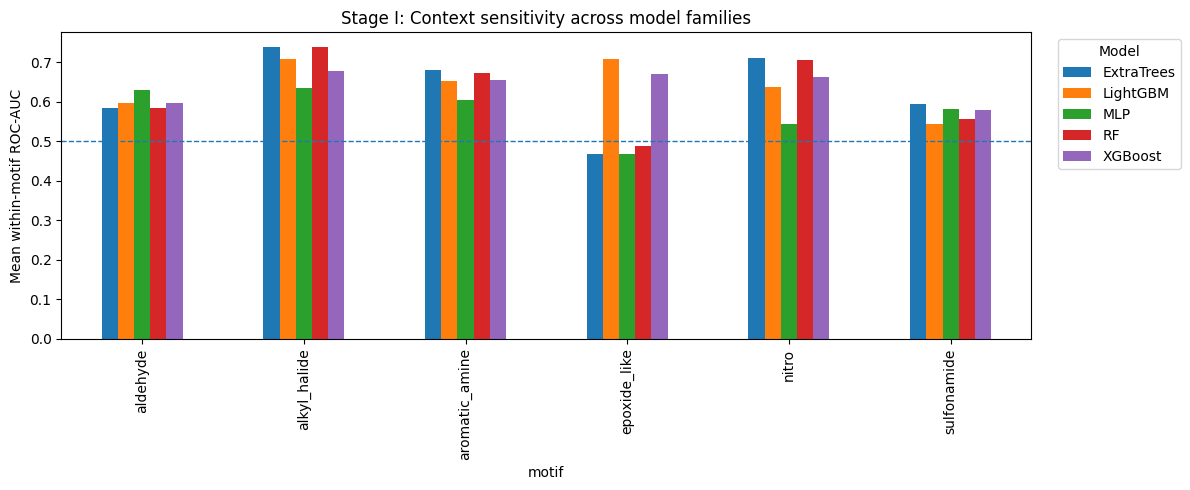

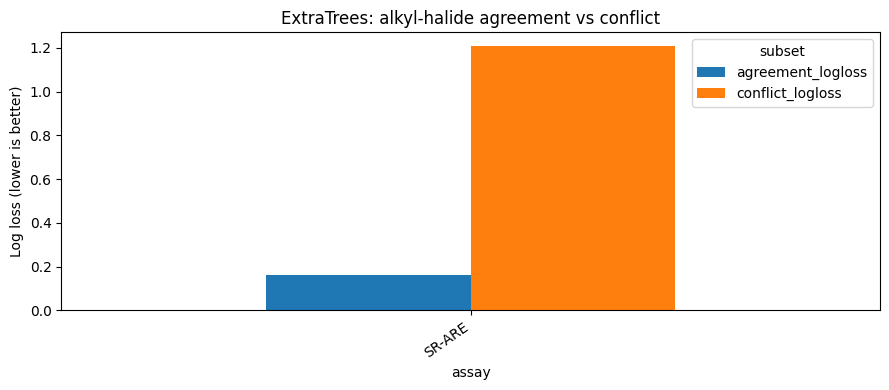

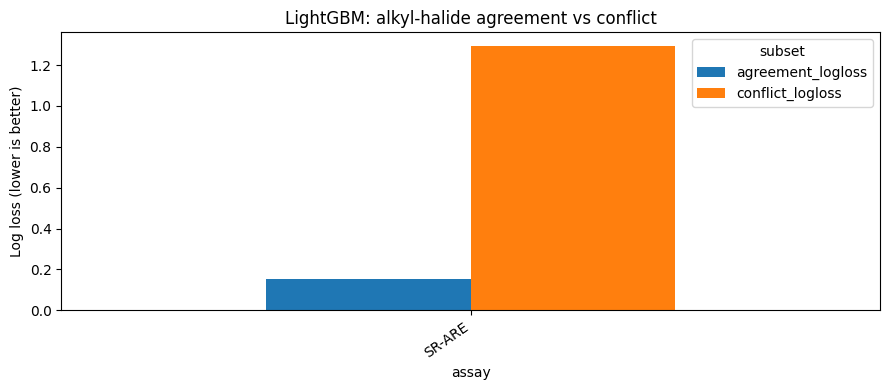

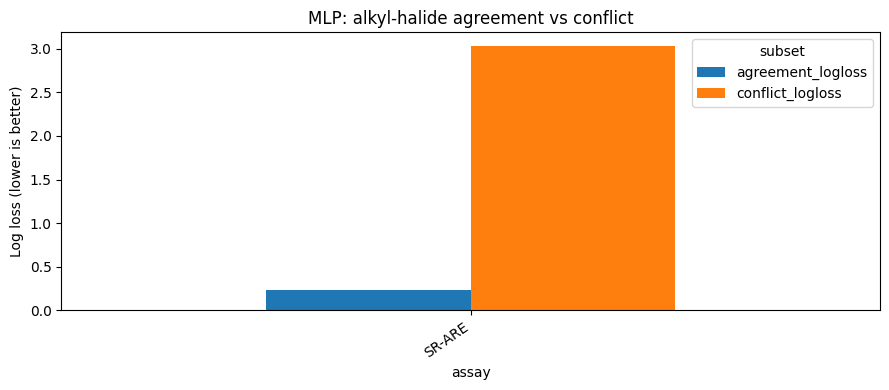

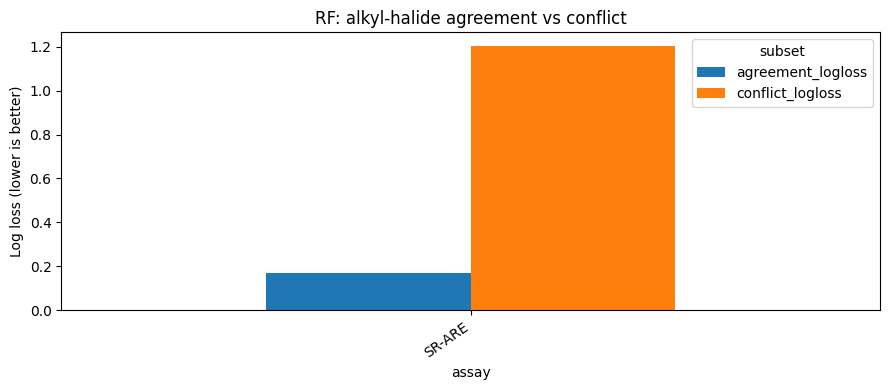

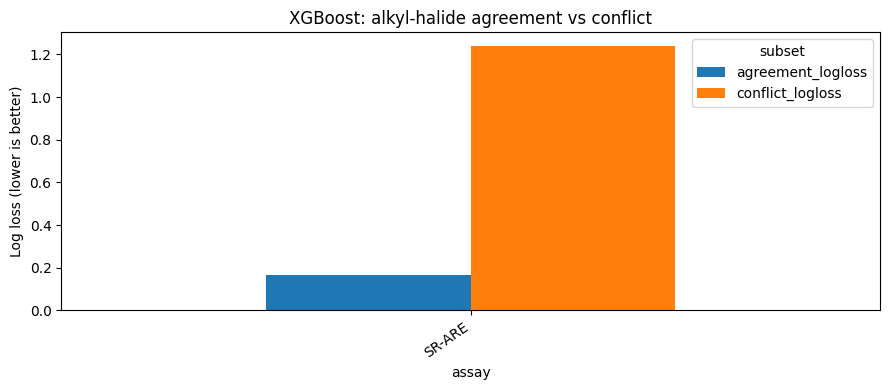

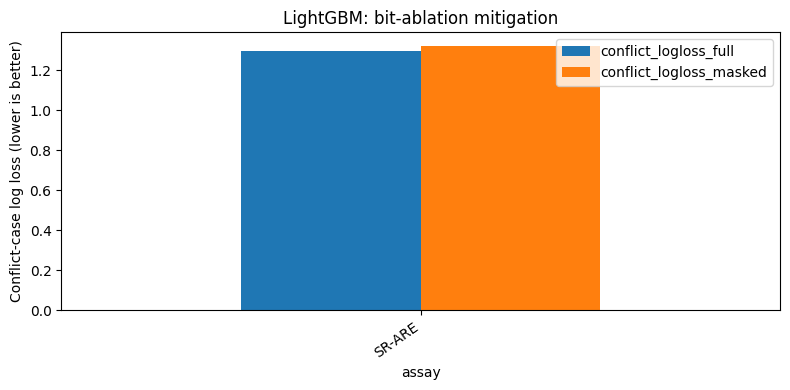

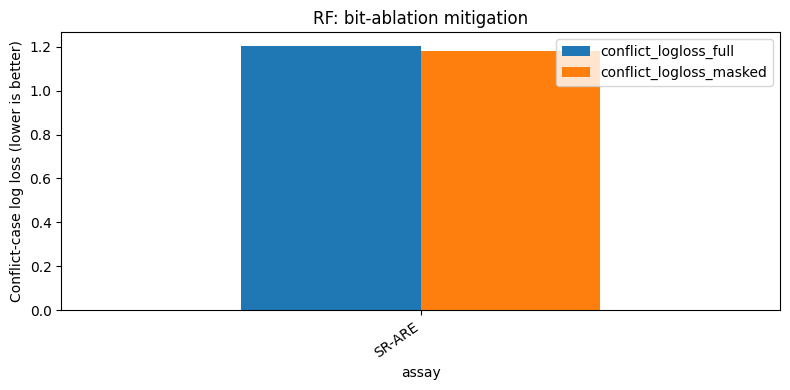

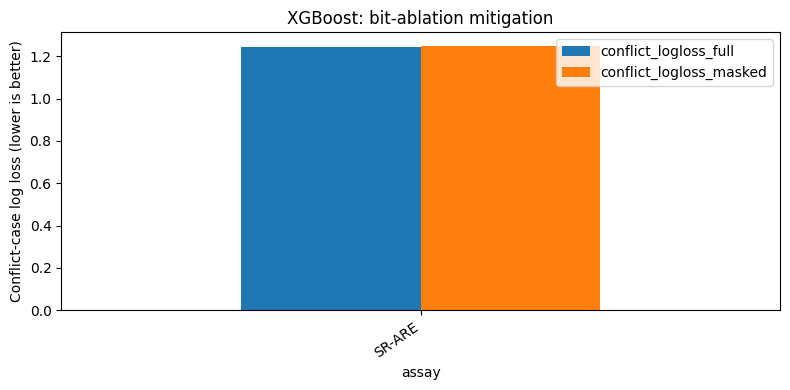

In [12]:
# Stage I: mean within-motif AUC by model for each motif
if len(stage1):
    s1plot = stage1.groupby(["model", "motif"], as_index=False)["within_motif_auc"].mean()
    pivot = s1plot.pivot(index="motif", columns="model", values="within_motif_auc")
    ax = pivot.plot(kind="bar", figsize=(12, 5))
    ax.axhline(0.5, linestyle="--", linewidth=1)
    ax.set_ylabel("Mean within-motif ROC-AUC")
    ax.set_title("Stage I: Context sensitivity across model families")
    ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()

# Stage II: conflict vs agreement log loss for the nominated motif
if len(stage2):
    s2 = stage2[stage2["motif"] == MITIGATION_MOTIF].copy()
    if len(s2):
        s2long = s2.melt(id_vars=["model", "assay"], value_vars=["agreement_logloss", "conflict_logloss"],
                          var_name="subset", value_name="log_loss")
        for model_name in s2long["model"].unique():
            sub = s2long[s2long["model"] == model_name]
            if len(sub):
                piv = sub.pivot(index="assay", columns="subset", values="log_loss")
                ax = piv.plot(kind="bar", figsize=(9, 4), title=f"{model_name}: alkyl-halide agreement vs conflict")
                ax.set_ylabel("Log loss (lower is better)")
                plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

# Stage III: compare mitigation results across models for the nominated motif
if len(stage3):
    valid = stage3.dropna(subset=["conflict_logloss_full", "conflict_logloss_masked"])
    if len(valid):
        for model_name in valid["model"].unique():
            sub = valid[valid["model"] == model_name]
            piv = sub.set_index("assay")[["conflict_logloss_full", "conflict_logloss_masked"]]
            ax = piv.plot(kind="bar", figsize=(8, 4), title=f"{model_name}: bit-ablation mitigation")
            ax.set_ylabel("Conflict-case log loss (lower is better)")
            plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

## 11. Export results and apply a cautious interpretation

Use the exported CSVs for tables/figures. Do not select a model or motif solely on these same evaluation results and then present its performance as confirmatory. Alkyl halide was nominated after the earlier RF screen, so this follow-up remains exploratory unless confirmed on a genuinely held-out endpoint or independent dataset.

In [13]:
stage1.to_csv("tox21_multimodel_stage1_context.csv", index=False)
stage2.to_csv("tox21_multimodel_stage2_conflict.csv", index=False)
stage3.to_csv("tox21_multimodel_stage3_mitigation.csv", index=False)
bootstrap_results.to_csv("tox21_multimodel_cluster_bootstrap.csv", index=False)
predictions.to_csv("tox21_multimodel_oof_predictions.csv", index=False)
assay_status.to_csv("tox21_multimodel_assay_status.csv", index=False)

print("Saved:")
for name in [
    "tox21_multimodel_stage1_context.csv", "tox21_multimodel_stage2_conflict.csv",
    "tox21_multimodel_stage3_mitigation.csv", "tox21_multimodel_cluster_bootstrap.csv",
    "tox21_multimodel_oof_predictions.csv", "tox21_multimodel_assay_status.csv"
]:
    print(" -", name)

print("\nInterpretation checklist:")
print("1. Compare within-motif AUC and conflict gaps across models, not just mean overall AUC.")
print("2. Report sample counts for every subgroup and model.")
print("3. A positive intervention improvement means lower conflict-case log loss; inspect overall performance trade-offs.")
print("4. Treat bootstrap intervals as unreliable when too few structural groups remain.")
print("5. The RF, ExtraTrees, XGBoost, LightGBM, and MLP results still use Morgan fingerprints. A follow-up graph model such as Chemprop D-MPNN is needed to test representation-level generalization.")

Saved:
 - tox21_multimodel_stage1_context.csv
 - tox21_multimodel_stage2_conflict.csv
 - tox21_multimodel_stage3_mitigation.csv
 - tox21_multimodel_cluster_bootstrap.csv
 - tox21_multimodel_oof_predictions.csv
 - tox21_multimodel_assay_status.csv

Interpretation checklist:
1. Compare within-motif AUC and conflict gaps across models, not just mean overall AUC.
2. Report sample counts for every subgroup and model.
3. A positive intervention improvement means lower conflict-case log loss; inspect overall performance trade-offs.
4. Treat bootstrap intervals as unreliable when too few structural groups remain.
5. The RF, ExtraTrees, XGBoost, LightGBM, and MLP results still use Morgan fingerprints. A follow-up graph model such as Chemprop D-MPNN is needed to test representation-level generalization.
